In [1]:
# ── Cell 1: Install ───────────────────────────────────────────────────────
!pip install -q transformers datasets torch torchaudio sentencepiece

In [2]:
import torch
 
class CFG:
    # models
    audio_model_name  = "facebook/hubert-base-ls960"
    text_model_name   = "sentence-transformers/all-MiniLM-L6-v2"
 
    # embedding dims
    audio_hidden_dim  = 768   # HuBERT-base output
    proj_dim          = 384   # match MiniLM output dim
 
    # audio
    sample_rate       = 16000
    max_audio_len     = 5     # seconds
 
    # hubert unfreezing
    unfreeze_last_n   = 4     # number of HuBERT transformer layers to unfreeze
 
    # training
    batch_size        = 32
    num_epochs        = 10
    lr                = 3e-5
    warmup_steps      = 500
    temperature       = 0.07  # InfoNCE temperature
 
    # loss weights
    lambda_mse        = 0.0
    lambda_cosine     = 1.0
    lambda_infonce    = 1.0
 
    # misc
    seed              = 42
    num_workers       = 2
    device            = "cuda" if torch.cuda.is_available() else "cpu"
    save_path         = "/kaggle/working/audio_encoder_distilled.pt"
 
    # dataset path — update to your Kaggle input path
    dataset_path      = "/kaggle/input/datasets/premsagars2023/medpub-tts/kd_dataset"
 
print(f"Device : {CFG.device}")
print(f"Unfreeze last {CFG.unfreeze_last_n} HuBERT layers")

Device : cuda
Unfreeze last 4 HuBERT layers


In [3]:
import os
import random
import json
import numpy as np
import pandas as pd
from pathlib import Path
 
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
 
import torchaudio
import torchaudio.transforms as T
 
from transformers import (
    HubertModel,
    AutoModel,
    AutoTokenizer,
    get_linear_schedule_with_warmup,
)
from tqdm.notebook import tqdm
 
# Reproducibility
random.seed(CFG.seed)
np.random.seed(CFG.seed)
torch.manual_seed(CFG.seed)
torch.cuda.manual_seed_all(CFG.seed)

In [4]:
class AudioTextDataset(Dataset):
    """
    Loads (query_text, audio_waveform) pairs from the KD dataset.
    Audio is resampled to CFG.sample_rate and padded/truncated to max_audio_len.
    """
    def __init__(self, dataset_path: str):
        parquet_path = Path(dataset_path) / "dataset.parquet"
        self.df = pd.read_parquet(parquet_path)
        self.max_samples = CFG.sample_rate * CFG.max_audio_len
        print(f"Dataset loaded: {len(self.df):,} pairs")
 
    def __len__(self):
        return len(self.df)
 
    def __getitem__(self, idx):
        row        = self.df.iloc[idx]
        query_text = row["query_text"]
        audio_path = row["audio_path"]

        audio_path = audio_path.replace("\\", "/")
        audio_path = audio_path.replace("kd_dataset/audio", "/kaggle/input/datasets/premsagars2023/medpub-tts/kd_dataset/audio")
        waveform, sr = torchaudio.load(audio_path)
 
        # Resample if needed
        if sr != CFG.sample_rate:
            waveform = T.Resample(sr, CFG.sample_rate)(waveform)
 
        # Mono
        if waveform.shape[0] > 1:
            waveform = waveform.mean(dim=0, keepdim=True)
 
        waveform = waveform.squeeze(0)  # (T,)
 
        # Pad or truncate
        if waveform.shape[0] < self.max_samples:
            waveform = F.pad(waveform, (0, self.max_samples - waveform.shape[0]))
        else:
            waveform = waveform[:self.max_samples]
 
        return query_text, waveform  # str, (T,)
 
 
dataset    = AudioTextDataset(CFG.dataset_path)
dataloader = DataLoader(
    dataset,
    batch_size  = CFG.batch_size,
    shuffle     = True,
    num_workers = CFG.num_workers,
    pin_memory  = True,
)

Dataset loaded: 30,000 pairs


In [5]:
text_tokenizer = AutoTokenizer.from_pretrained(CFG.text_model_name)
text_encoder   = AutoModel.from_pretrained(CFG.text_model_name).to(CFG.device)
 
# Freeze entirely — teacher never updates
for param in text_encoder.parameters():
    param.requires_grad = False
text_encoder.eval()
 
def encode_texts_teacher(texts: list[str]) -> torch.Tensor:
    """
    Encode a batch of texts with the frozen teacher.
    Returns L2-normalised embeddings of shape (B, proj_dim).
    """
    encoded = text_tokenizer(
        texts,
        padding=True,
        truncation=True,
        max_length=128,
        return_tensors="pt",
    ).to(CFG.device)
    with torch.no_grad():
        out  = text_encoder(**encoded)
        mask = encoded["attention_mask"]
        embs = (out.last_hidden_state * mask.unsqueeze(-1)).sum(1) / mask.sum(-1, keepdim=True)
        embs = F.normalize(embs, p=2, dim=-1)
    return embs  # (B, proj_dim)
 
print(f"Teacher loaded & frozen: {CFG.text_model_name}")

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/90.9M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Teacher loaded & frozen: sentence-transformers/all-MiniLM-L6-v2


In [6]:
class AttentionPooling(nn.Module):
    def __init__(self, hidden_dim):
        super().__init__()
        self.attn = nn.Linear(hidden_dim, 1)

    def forward(self, hidden_states):  # (B, T', 768)
        weights = torch.softmax(self.attn(hidden_states), dim=1)  # (B, T', 1)
        return (hidden_states * weights).sum(dim=1)               # (B, 768)

In [7]:
class AudioEncoder(nn.Module):
    """
    HuBERT backbone with a linear projection head.
    Last N transformer layers are unfrozen; rest frozen.
    Output is L2-normalised, matching teacher embedding space.
    """
    def __init__(self):
        super().__init__()
        self.hubert = HubertModel.from_pretrained(CFG.audio_model_name)
        self.proj = nn.Sequential(
            nn.Linear(CFG.audio_hidden_dim, CFG.audio_hidden_dim),
            nn.GELU(),
            nn.LayerNorm(CFG.audio_hidden_dim),
            nn.Linear(CFG.audio_hidden_dim, CFG.proj_dim),
        )
        self.pool = AttentionPooling(CFG.audio_hidden_dim)
        self._freeze_layers()
 
    def _freeze_layers(self):
        # Freeze everything first
        for param in self.hubert.parameters():
            param.requires_grad = False
 
        # Unfreeze last N transformer layers
        total_layers  = len(self.hubert.encoder.layers)
        unfreeze_from = total_layers - CFG.unfreeze_last_n
        for i, layer in enumerate(self.hubert.encoder.layers):
            if i >= unfreeze_from:
                for param in layer.parameters():
                    param.requires_grad = True
 
        trainable = sum(p.numel() for p in self.parameters() if p.requires_grad)
        total     = sum(p.numel() for p in self.parameters())
        print(f"Trainable params: {trainable:,} / {total:,} "
              f"({100*trainable/total:.1f}%) — last {CFG.unfreeze_last_n} layers + proj")
 
    def forward(self, waveforms: torch.Tensor) -> torch.Tensor:
        """
        Args:
            waveforms : (B, T) raw 16kHz audio
        Returns:
            embeddings: (B, proj_dim) L2-normalised
        """
        out    = self.hubert(input_values=waveforms).last_hidden_state  # (B, T', 768)
        pooled = self.pool(out)                                         # (B, 768)
        proj   = self.proj(pooled)                                       # (B, proj_dim)
        return F.normalize(proj, p=2, dim=-1)                           # (B, proj_dim)
 
 
audio_encoder = AudioEncoder().to(CFG.device)
print(f"Student loaded: {CFG.audio_model_name}")

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/378M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

Trainable params: 29,239,681 / 95,259,905 (30.7%) — last 4 layers + proj
Student loaded: facebook/hubert-base-ls960


In [8]:
def mse_loss(audio_emb: torch.Tensor, text_emb: torch.Tensor) -> torch.Tensor:
    """Element-wise MSE between student and teacher embeddings."""
    return F.mse_loss(audio_emb, text_emb)
 
 
def cosine_loss(audio_emb: torch.Tensor, text_emb: torch.Tensor) -> torch.Tensor:
    """1 - cosine similarity, averaged over batch."""
    return 1.0 - F.cosine_similarity(audio_emb, text_emb, dim=-1).mean()
 
 
def infonce_loss(audio_emb: torch.Tensor, text_emb: torch.Tensor) -> torch.Tensor:
    """
    Symmetric InfoNCE (contrastive) loss.
    Diagonal of the similarity matrix = positive pairs.
    """
    logits = (audio_emb @ text_emb.T) / CFG.temperature  # (B, B)
    labels = torch.arange(logits.shape[0], device=logits.device)
    loss_a = F.cross_entropy(logits,   labels)  # audio → text
    loss_t = F.cross_entropy(logits.T, labels)  # text  → audio
    return (loss_a + loss_t) / 2.0
 
 
def combined_loss(
    audio_emb: torch.Tensor,
    text_emb:  torch.Tensor,
) -> tuple[torch.Tensor, dict]:
    """
    Weighted sum of MSE + Cosine + InfoNCE losses.
    Returns total loss and a dict of individual losses for logging.
    """
    l_mse     = mse_loss(audio_emb, text_emb)
    l_cosine  = cosine_loss(audio_emb, text_emb)
    l_infonce = infonce_loss(audio_emb, text_emb)
 
    total = (
        CFG.lambda_mse     * l_mse     +
        CFG.lambda_cosine  * l_cosine  +
        CFG.lambda_infonce * l_infonce
    )
    return total, {
        "mse"    : l_mse.item(),
        "cosine" : l_cosine.item(),
        "infonce": l_infonce.item(),
        "total"  : total.item(),
    }

In [9]:
optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, audio_encoder.parameters()),
    lr=CFG.lr,
)
 
total_steps = len(dataloader) * CFG.num_epochs
scheduler   = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps   = CFG.warmup_steps,
    num_training_steps = total_steps,
)
 
print(f"Total training steps : {total_steps:,}")
print(f"Warmup steps         : {CFG.warmup_steps}")

Total training steps : 9,380
Warmup steps         : 500


In [10]:
history = []  # list of { epoch, mse, cosine, infonce, total }
 
for epoch in range(1, CFG.num_epochs + 1):
    audio_encoder.train()
    epoch_losses = {"mse": 0., "cosine": 0., "infonce": 0., "total": 0.}
 
    pbar = tqdm(dataloader, desc=f"Epoch {epoch}/{CFG.num_epochs}")
    for texts, waveforms in pbar:
        waveforms = waveforms.to(CFG.device)  # (B, T)
 
        # Teacher: frozen text embeddings
        text_emb  = encode_texts_teacher(list(texts))  # (B, proj_dim)
 
        # Student: audio embeddings
        audio_emb = audio_encoder(waveforms)            # (B, proj_dim)
 
        # Loss
        loss, loss_dict = combined_loss(audio_emb, text_emb)
 
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            filter(lambda p: p.requires_grad, audio_encoder.parameters()), 1.0
        )
        optimizer.step()
        scheduler.step()
 
        for k in epoch_losses:
            epoch_losses[k] += loss_dict[k]
 
        pbar.set_postfix({
            "total"  : f"{loss_dict['total']:.4f}",
            "mse"    : f"{loss_dict['mse']:.4f}",
            "cos"    : f"{loss_dict['cosine']:.4f}",
            "nce"    : f"{loss_dict['infonce']:.4f}",
        })
 
    # Epoch summary
    n   = len(dataloader)
    avg = {k: v / n for k, v in epoch_losses.items()}
    avg["epoch"] = epoch
    history.append(avg)
 
    print(
        f"Epoch {epoch:02d} | "
        f"total={avg['total']:.4f} | "
        f"mse={avg['mse']:.4f} | "
        f"cosine={avg['cosine']:.4f} | "
        f"infonce={avg['infonce']:.4f}"
    )
 
    # Save checkpoint every epoch
    torch.save({
        "epoch"      : epoch,
        "model_state": audio_encoder.state_dict(),
        "optim_state": optimizer.state_dict(),
        "cfg": {
            "audio_model_name": CFG.audio_model_name,
            "audio_hidden_dim": CFG.audio_hidden_dim,
            "proj_dim"        : CFG.proj_dim,
            "unfreeze_last_n" : CFG.unfreeze_last_n,
        },
    }, CFG.save_path)
 
print(f"\nTraining complete. Model saved to: {CFG.save_path}")

Epoch 1/10:   0%|          | 0/938 [00:00<?, ?it/s]

model.safetensors:   0%|          | 0.00/378M [00:00<?, ?B/s]

Epoch 01 | total=3.2921 | mse=0.0042 | cosine=0.8094 | infonce=2.4827


Epoch 2/10:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch 02 | total=1.5522 | mse=0.0033 | cosine=0.6331 | infonce=0.9192


...

Epoch 08 | total=0.7290 | mse=0.0024 | cosine=0.4555 | infonce=0.2735


Epoch 9/10:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch 09 | total=0.6905 | mse=0.0023 | cosine=0.4445 | infonce=0.2460


Epoch 10/10:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch 10 | total=0.6825 | mse=0.0023 | cosine=0.4413 | infonce=0.2411

Training complete. Model saved to: /kaggle/working/audio_encoder_distilled.pt


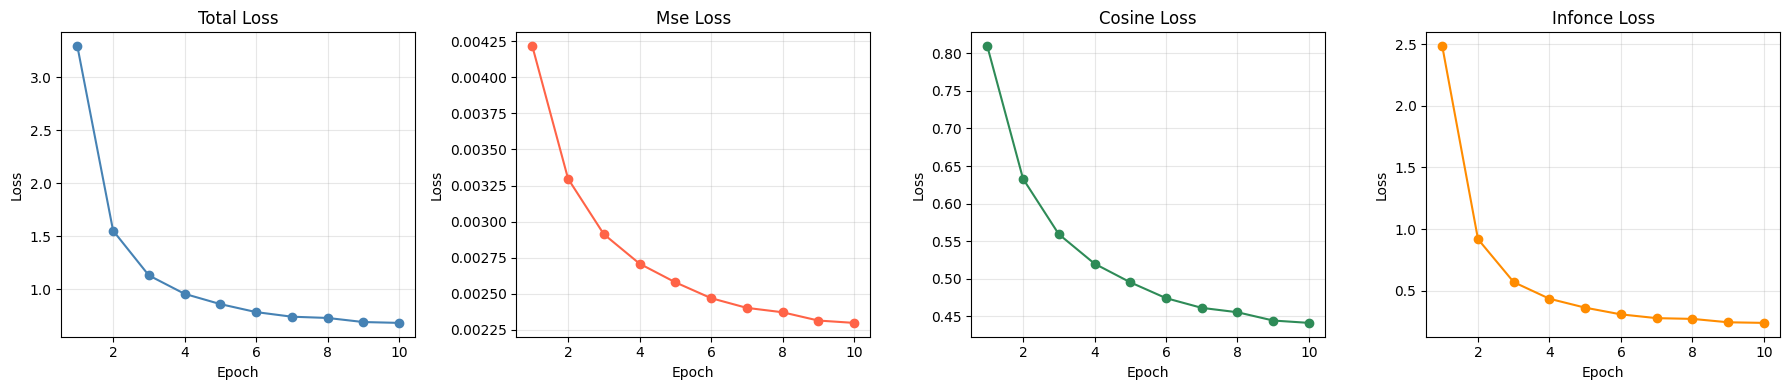

In [11]:
import matplotlib.pyplot as plt
 
epochs = [h["epoch"] for h in history]
 
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, key, color in zip(
    axes,
    ["total", "mse", "cosine", "infonce"],
    ["steelblue", "tomato", "seagreen", "darkorange"]
):
    ax.plot(epochs, [h[key] for h in history], marker="o", color=color)
    ax.set_title(f"{key.capitalize()} Loss")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.grid(True, alpha=0.3)
 
plt.tight_layout()
plt.savefig("/kaggle/working/kd_loss_curves.png", dpi=150)
plt.show()


In [12]:
from IPython.display import FileLink
display(FileLink(r'/kaggle/working/audio_encoder_distilled.pt')) # Replace 'df_name.csv' with your filename


/kaggle/working/audio_encoder_distilled.pt